In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("vgsales.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Dataset dimensions
print("Shape:", df.shape)
# Column data types and non-null values
df.info()
display(df.head())
display(df.tail())
# Memory usage
print("Memory usage:")
print(df.memory_usage(deep=True))
print("Total memory:", df.memory_usage(deep=True).sum(), "bytes")

Shape: (16598, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


Memory usage:
Index               132
Rank             132784
Name            1211976
Platform         859224
Year             132784
Genre            931806
Publisher       1037824
NA_Sales         132784
EU_Sales         132784
JP_Sales         132784
Other_Sales      132784
Global_Sales     132784
dtype: int64
Total memory: 4970450 bytes


,Missing Count,Missing Percentage
Year,271,1.632727
Publisher,58,0.349440
Rank,0,0.000000
Name,0,0.000000
Platform,0,0.000000
Genre,0,0.000000
NA_Sales,0,0.000000
EU_Sales,0,0.000000
JP_Sales,0,0.000000
Other_Sales,0,0.000000


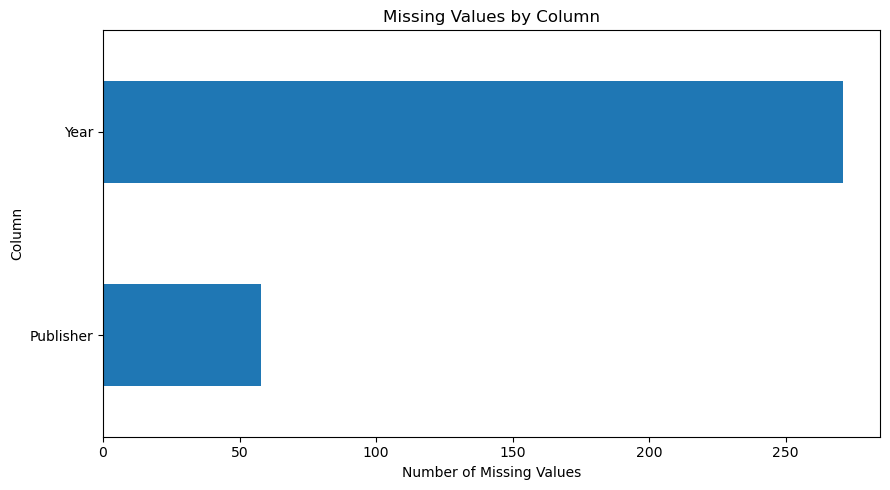

In [4]:
# Count missing values in each column
missing = df.isnull().sum()
# Calculate missing percentages
missing_percent = (missing / len(df)) * 100
missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})
display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))
# Visualize missing values
missing[missing > 0].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Missing Values by Column"
)

plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [5]:
# Numeric statistics
display(df.describe().T)
display(df.select_dtypes(include="number").median())
print(df["Genre"].value_counts())
print(df["Platform"].value_counts().head(10))

,count,mean,std,min,25%,50%,75%,max
Rank,16598.0,8300.605254,4791.853933,1.00,4151.25,8300.50,12449.75,16600.00
Year,16327.0,2006.406443,5.828981,1980.00,2003.00,2007.00,2010.00,2020.00
NA_Sales,16598.0,0.264667,0.816683,0.00,0.00,0.08,0.24,41.49
EU_Sales,16598.0,0.146652,0.505351,0.00,0.00,0.02,0.11,29.02
JP_Sales,16598.0,0.077782,0.309291,0.00,0.00,0.00,0.04,10.22
Other_Sales,16598.0,0.048063,0.188588,0.00,0.00,0.01,0.04,10.57
Global_Sales,16598.0,0.537441,1.555028,0.01,0.06,0.17,0.47,82.74


Rank            8300.50
Year            2007.00
NA_Sales           0.08
EU_Sales           0.02
JP_Sales           0.00
Other_Sales        0.01
Global_Sales       0.17
dtype: float64

Genre
Action          3316
Sports          2346
Misc            1739
Role-Playing    1488
Shooter         1310
Adventure       1286
Racing          1249
Platform         886
Simulation       867
Fighting         848
Strategy         681
Puzzle           582
Name: count, dtype: int64
Platform
DS      2163
PS2     2161
PS3     1329
Wii     1325
X360    1265
PSP     1213
PS      1196
PC       960
XB       824
GBA      822
Name: count, dtype: int64


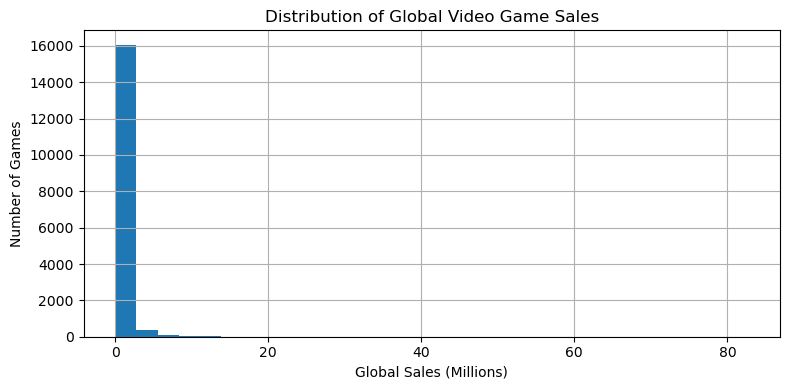

In [6]:
df["Global_Sales"].hist(bins=30, figsize=(8, 4))
plt.title("Distribution of Global Video Game Sales")
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Number of Games")
plt.tight_layout()
plt.show()

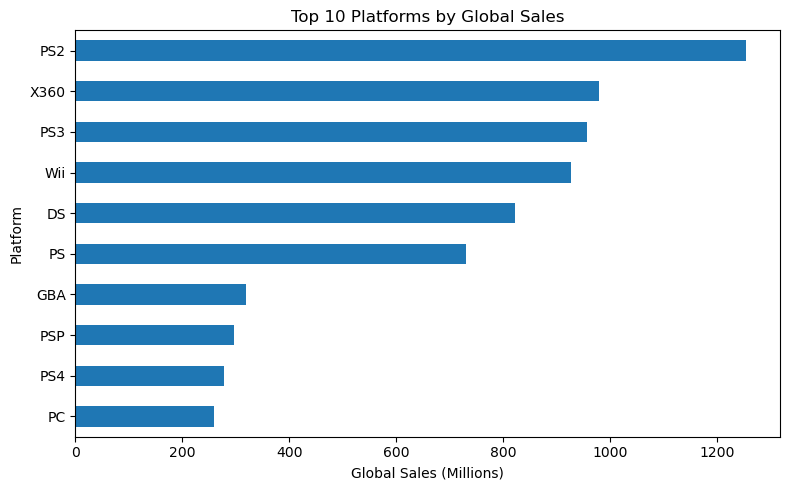

In [12]:
platform_sales = df.groupby("Platform")["Global_Sales"].sum()
top_platforms = platform_sales.nlargest(10).sort_values()
top_platforms.plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Platforms by Global Sales")
plt.xlabel("Global Sales (Millions)")
plt.ylabel("Platform")
plt.tight_layout()
plt.show()

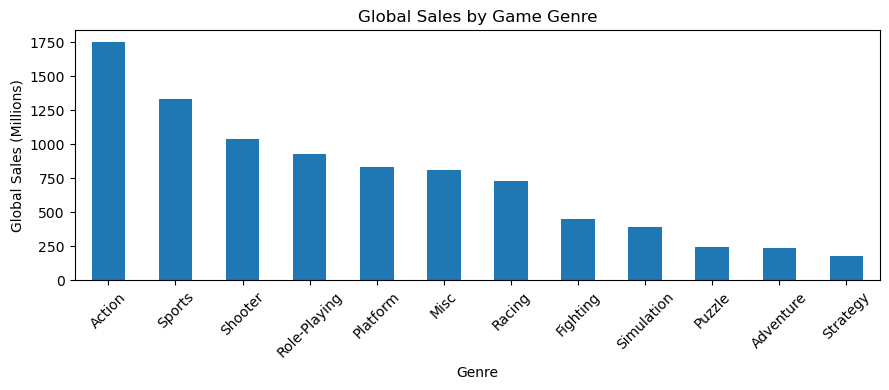

In [9]:
genre_sales = df.groupby("Genre")["Global_Sales"].sum()
genre_sales = genre_sales.sort_values(ascending=False)
genre_sales.plot(kind="bar", figsize=(9, 4))
plt.title("Global Sales by Game Genre")
plt.xlabel("Genre")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

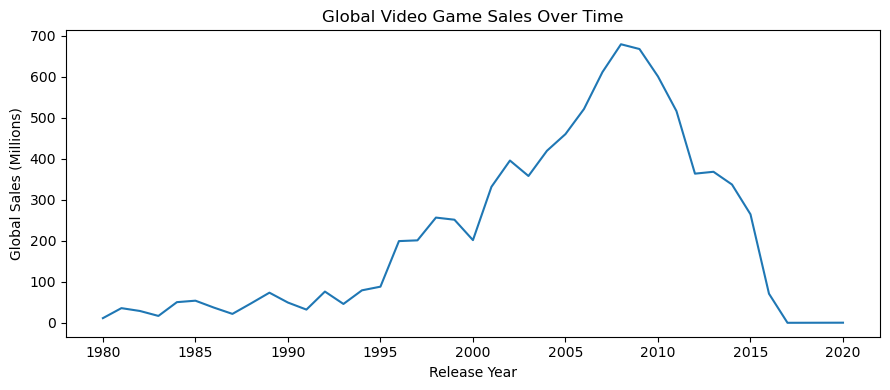

In [10]:
yearly_sales = (
    df.dropna(subset=["Year"])
      .groupby("Year")["Global_Sales"]
      .sum()
)
yearly_sales.plot(figsize=(9, 4))
plt.title("Global Video Game Sales Over Time")
plt.xlabel("Release Year")
plt.ylabel("Global Sales (Millions)")
plt.tight_layout()
plt.show()

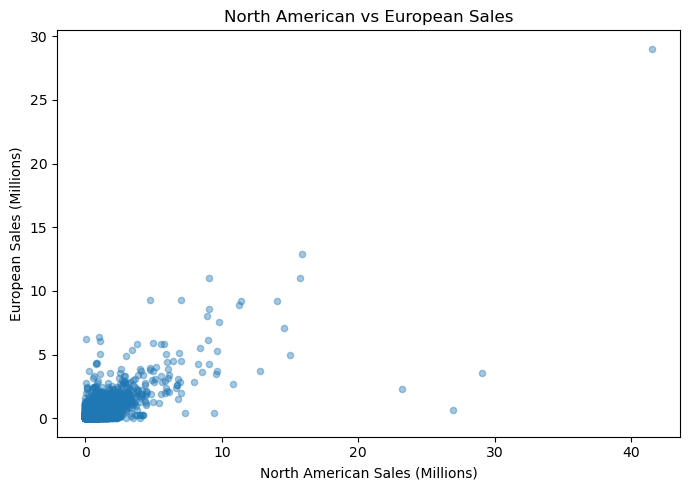

In [11]:
df.plot(
    kind="scatter",
    x="NA_Sales",
    y="EU_Sales",
    alpha=0.4,
    figsize=(7, 5)
)
plt.title("North American vs European Sales")
plt.xlabel("North American Sales (Millions)")
plt.ylabel("European Sales (Millions)")
plt.tight_layout()
plt.show()